# 01 — Exploration des données EnerVision

## Objectif

Ce notebook vise à analyser les données énergétiques collectées depuis l'API EnerVision afin d'évaluer leur qualité et leur pertinence pour les futurs modèles de Machine Learning.

L'analyse portera sur la structure du dataset, les distributions, les valeurs manquantes, la cohérence temporelle et les éventuelles anomalies physiques.

**Attention :** les précédents tests ont révélé que l'API pouvait générer des valeurs différentes pour une même période. Les résultats de cette exploration doivent donc être interprétés comme ceux de données synthétiques.

## Prérequis — Collecte des données

Ce notebook exploite les données énergétiques issues de l'API EnerVision, préalablement collectées et enregistrées au format JSON.

**Avant toute exécution du notebook**, il est nécessaire de lancer le script de collecte depuis le répertoire `ml/` :

```powershell
python scripts/collect_readings.py
```

Ce script récupère les mesures des sept sites sur une période de 24 heures et les enregistre dans le répertoire `data/raw/`.

**Points d'attention :**

- L'environnement virtuel Python doit être configuré avec les dépendances du projet.
- Le fichier `.env` doit contenir les paramètres d'authentification nécessaires à l'API.
- Les données étant synthétiques et potentiellement régénérées à chaque requête, deux collectes successives peuvent produire des résultats différents.
- Les fichiers bruts ne doivent pas être modifiés par les traitements du notebook.

Une fois les fichiers générés, les cellules suivantes peuvent être exécutées dans l'ordre.

A - Chargement des fichiers JSON
- Attendu : 7 sites pour 1000 mesures / site

In [54]:
import json
from pathlib import Path

import pandas as pd

# Notre notebook se trouve dans ml/notebooks/
RAW_DIR = Path("../data/raw")

records = []

files = sorted(RAW_DIR.glob("*.json"))

print(f"Fichiers trouvés : {len(files)}")

for file in files:
    with file.open(encoding="utf-8") as f:
        payload = json.load(f)

    for reading in payload["readings"]:
        records.append({
            **reading,
            "collected_at": payload["collected_at"],
            "source_file": file.name,
        })

if not records:
    raise ValueError("Aucune mesure trouvée dans data/raw")

df = pd.DataFrame(records)

df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)
df["collected_at"] = pd.to_datetime(df["collected_at"], utc=True)

print(f"Nombre de mesures : {len(df)}")
print(f"Nombre de sites : {df['site_id'].nunique()}")

display(df.head())

Fichiers trouvés : 7
Nombre de mesures : 7000
Nombre de sites : 7


,timestamp,site_id,site_type,consumption_kw,consumption_kwh,voltage_v,current_a,power_factor,temperature_celsius,humidity_percent,null_reasons,data_quality,collected_at,source_file
0,2026-10-21 09:27:00.985617+00:00,SITE001,office,130.87,130.87,400.7,198.52,0.948,8.3,44.0,[],good,2026-10-22 09:32:00.985617+00:00,SITE001_20261022_093200.json
1,2026-10-21 09:28:27.385617+00:00,SITE001,office,127.71,127.71,403.2,192.49,0.922,8.3,42.8,[],good,2026-10-22 09:32:00.985617+00:00,SITE001_20261022_093200.json
2,2026-10-21 09:29:53.785617+00:00,SITE001,office,NaN,NaN,NaN,NaN,NaN,NaN,NaN,[network_loss],critical,2026-10-22 09:32:00.985617+00:00,SITE001_20261022_093200.json
3,2026-10-21 09:31:20.185617+00:00,SITE001,office,127.70,127.70,406.0,191.14,0.921,7.8,39.5,[],good,2026-10-22 09:32:00.985617+00:00,SITE001_20261022_093200.json
4,2026-10-21 09:32:46.585617+00:00,SITE001,office,129.27,129.27,398.3,197.23,0.926,8.4,39.9,[],good,2026-10-22 09:32:00.985617+00:00,SITE001_20261022_093200.json


B - Structure du Dataset
 - Vérifier que les mesures ont été correctement chargées et que les variables numériques sont exploitables

In [55]:
print("Dimensions :", df.shape)

print("\nTypes des colonnes :")
display(df.dtypes.to_frame("Type"))

print("\nMesures par site :")
display(
    df.groupby(["site_id", "site_type"])
    .size()
    .rename("Nombre de mesures")
    .to_frame()
)

print("\nStatistiques descriptives :")
display(df.describe().T)

Dimensions : (7000, 14)

Types des colonnes :


,Type
timestamp,"datetime64[us, UTC]"
site_id,str
site_type,str
consumption_kw,float64
consumption_kwh,float64
voltage_v,float64
current_a,float64
power_factor,float64
temperature_celsius,float64
humidity_percent,float64



Mesures par site :


,,Nombre de mesures
site_id,site_type,
SITE001,office,1000
SITE002,factory,1000
SITE003,datacenter,1000
SITE004,retail,1000
SITE005,hospital,1000
SITE006,office,1000
SITE007,factory,1000



Statistiques descriptives :


,count,mean,std,min,25%,50%,75%,max
consumption_kw,6581.0,417.719736,302.936847,46.47,132.4000,343.430,723.4200,1044.66
consumption_kwh,6581.0,417.719736,302.936847,46.47,132.4000,343.430,723.4200,1044.66
voltage_v,6572.0,399.924391,4.939529,379.00,396.6000,399.900,403.2000,418.70
current_a,6572.0,634.374553,460.025335,70.81,201.2175,522.540,1100.9275,1606.55
power_factor,6572.0,0.919037,0.028916,0.85,0.8990,0.919,0.9400,0.98
temperature_celsius,6385.0,5.039483,4.028823,-7.20,1.8000,5.000,8.3000,17.60
humidity_percent,6435.0,42.621368,4.870011,30.00,39.3000,42.700,45.9000,59.70


## 2 — Analyse de la qualité des données

Cette section vise à identifier les valeurs manquantes, à examiner les indicateurs de qualité fournis par l'API et à détecter les éventuelles incohérences entre variables.

L'objectif est de déterminer les traitements nécessaires avant toute phase de modélisation.

A - Analyse des valeurs manquantes

In [56]:
missing = pd.DataFrame({
    "Valeurs manquantes": df.isna().sum(),
    "Pourcentage (%)": (df.isna().mean() * 100).round(2),
})

display(
    missing.sort_values(
        "Pourcentage (%)",
        ascending=False
    )
)

,Valeurs manquantes,Pourcentage (%)
temperature_celsius,615,8.79
humidity_percent,565,8.07
current_a,428,6.11
power_factor,428,6.11
voltage_v,428,6.11
consumption_kw,419,5.99
consumption_kwh,419,5.99
site_type,0,0.00
timestamp,0,0.00
site_id,0,0.00


B - Qualité déclarée par l'API
 - Vérification et count de data_quality au global
 - Répartition par site en pourcentage

In [57]:
print("Répartition de data_quality :")

display(
    df["data_quality"]
    .value_counts(dropna=False)
    .to_frame("Nombre de mesures")
)

print("\nRépartition par site :")

display(
    pd.crosstab(
        df["site_id"],
        df["data_quality"],
        normalize="index"
    ).mul(100).round(2)
)

Répartition de data_quality :


,Nombre de mesures
data_quality,
good,5517
partial,1237
critical,146
degraded,100



Répartition par site :


data_quality,critical,degraded,good,partial
site_id,,,,
SITE001,3.2,1.6,77.7,17.5
SITE002,1.9,1.0,79.8,17.3
SITE003,1.5,1.7,78.4,18.4
SITE004,2.2,1.6,79.0,17.2
SITE005,2.1,1.3,77.8,18.8
SITE006,1.9,1.2,80.3,16.6
SITE007,1.8,1.6,78.7,17.9


C - Vérification de kW et kWh
 - Les données kW et kWh semblent systématiquement correspondre. Etude de ce cas de figure

In [58]:
valid = df[
    ["consumption_kw", "consumption_kwh"]
].dropna()

identical = (
    valid["consumption_kw"]
    == valid["consumption_kwh"]
)

print(f"Mesures comparables : {len(valid)}")
print(f"Valeurs identiques : {identical.sum()}")
print(f"Pourcentage identique : {identical.mean() * 100:.2f}%")

Mesures comparables : 6581
Valeurs identiques : 6581
Pourcentage identique : 100.00%


## 3 — Analyse des valeurs manquantes et des indicateurs de qualité

Les valeurs manquantes ne sont pas systématiquement considérées comme des anomalies à supprimer.

L'API EnerVision fournit deux métadonnées complémentaires :

- `data_quality` : niveau de qualité déclaré pour chaque mesure.
- `null_reasons` : informations relatives aux causes d'absence de certaines valeurs.

Cette analyse vise à déterminer si les valeurs manquantes sont cohérentes avec ces indicateurs, afin d'orienter les futurs choix de prétraitement.

A - Valeurs manquantes selon la qualité
 - Examen du nombre de valeurs manquantes pour chaque catégorie de qualité

In [59]:
measure_columns = [
    "consumption_kw",
    "consumption_kwh",
    "voltage_v",
    "current_a",
    "power_factor",
    "temperature_celsius",
    "humidity_percent",
]

df["missing_count"] = df[measure_columns].isna().sum(axis=1)

display(
    df.groupby("data_quality")["missing_count"]
    .agg(["count", "mean", "min", "max"])
    .round(2)
)

,count,mean,min,max
data_quality,,,,
critical,146,7.00,7,7
degraded,100,3.30,2,6
good,5517,0.00,0,0
partial,1237,1.58,1,3


B - Explorer les null_reasons

In [60]:
print("Exemples de null_reasons :")

display(
    df.loc[
        df["missing_count"] > 0,
        ["site_id", "data_quality", "missing_count", "null_reasons"]
    ].head(15)
)

print("\nTypes de données présents :")

display(
    df["null_reasons"]
    .map(lambda x: type(x).__name__)
    .value_counts()
)

Exemples de null_reasons :


,site_id,data_quality,missing_count,null_reasons
2,SITE001,critical,7,[network_loss]
12,SITE001,partial,1,[temperature_sensor_failure]
23,SITE001,degraded,6,"[consumption_sensor_failure, electrical_sensor..."
24,SITE001,partial,2,[consumption_sensor_failure]
29,SITE001,partial,3,[electrical_sensor_failure]
31,SITE001,partial,2,[consumption_sensor_failure]
32,SITE001,partial,1,[temperature_sensor_failure]
35,SITE001,partial,1,[temperature_sensor_failure]
39,SITE001,partial,3,[electrical_sensor_failure]
41,SITE001,partial,3,[electrical_sensor_failure]



Types de données présents :


null_reasons
list    7000
Name: count, dtype: int64

C - Vérifier la cohérence des indicateurs : 
- Est ce que des mesures "good" contiennent des valeurs manquantes?

In [61]:
df["has_missing"] = df["missing_count"] > 0

display(
    pd.crosstab(
        df["data_quality"],
        df["has_missing"],
        margins=True
    )
)

has_missing,False,True,All
data_quality,,,
critical,0,146,146
degraded,0,100,100
good,5517,0,5517
partial,0,1237,1237
All,5517,1483,7000


D - Détail du nombre de null_reasons

In [62]:
from collections import Counter

reason_counts = Counter(
    reason
    for reasons in df["null_reasons"]
    for reason in reasons
)

display(
    pd.DataFrame(
        reason_counts.items(),
        columns=["Raison", "Occurrences"]
    ).sort_values("Occurrences", ascending=False)
)

,Raison,Occurrences
1,temperature_sensor_failure,469
4,humidity_sensor_failure,419
3,electrical_sensor_failure,282
2,consumption_sensor_failure,273
0,network_loss,146


E - Variables manquantes selon la qualité

In [63]:
missing_by_quality = (
    df.groupby("data_quality")[measure_columns]
    .apply(lambda group: group.isna().mean() * 100)
    .round(2)
)

display(missing_by_quality)

,consumption_kw,consumption_kwh,voltage_v,current_a,power_factor,temperature_celsius,humidity_percent
data_quality,,,,,,,
critical,100.00,100.00,100.00,100.00,100.00,100.00,100.00
degraded,44.00,44.00,40.00,40.00,40.00,66.00,56.00
good,0.00,0.00,0.00,0.00,0.00,0.00,0.00
partial,18.51,18.51,19.56,19.56,19.56,32.58,29.35


### Conclusion — Gestion des valeurs manquantes

L'analyse des 7 000 mesures met en évidence une relation systématique entre les valeurs manquantes et les indicateurs de qualité fournis par l'API EnerVision.

Les observations classées `good` ne présentent aucune valeur manquante, tandis que les observations `partial`, `degraded` et `critical` présentent des niveaux croissants d'indisponibilité.

Les informations contenues dans `null_reasons` permettent également d'identifier différentes causes potentielles, notamment les défaillances de capteurs et les pertes de communication.

**Décision retenue :** aucune suppression systématique des observations contenant des valeurs manquantes ne sera effectuée à ce stade.

Les données brutes seront conservées intégralement. Les stratégies d'exclusion ou d'imputation seront définies ultérieurement en fonction des besoins spécifiques des modèles de Machine Learning.

Cette approche permet de préserver les informations relatives à la qualité des mesures et d'envisager leur exploitation pour des fonctionnalités de surveillance ou de détection d'anomalies.

## 4 — Analyse comparative des sites

### Objectif

Cette analyse vise à identifier les différences de comportement énergétique entre les sites et les catégories de bâtiments.

Elle doit contribuer au choix de la stratégie de modélisation :

- Un modèle global commun à l'ensemble des sites.
- Un modèle spécialisé par catégorie de bâtiment.
- Un modèle individualisé pour chaque site.

Les premières comparaisons porteront sur les distributions de consommation, leur variabilité et les éventuelles différences entre sites d'une même catégorie.

Ces observations seront ensuite complétées par une analyse temporelle et par des expérimentations comparatives des modèles.

A - Statistiques énergétiques par site. Le coefficient de variation (cv_percent) permet de comparer la variabilité relative des consommations, même lorsque des sites ont des puissances très différentes

In [64]:
site_stats = (
    df.groupby(["site_id", "site_type"])
    .agg(
        observations=("consumption_kw", "count"),
        mean_kw=("consumption_kw", "mean"),
        median_kw=("consumption_kw", "median"),
        std_kw=("consumption_kw", "std"),
        min_kw=("consumption_kw", "min"),
        max_kw=("consumption_kw", "max"),
    )
    .round(2)
)

site_stats["cv_percent"] = (
    site_stats["std_kw"] / site_stats["mean_kw"] * 100
).round(2)

display(site_stats)

,,observations,mean_kw,median_kw,std_kw,min_kw,max_kw,cv_percent
site_id,site_type,,,,,,,
SITE001,office,927,105.03,66.59,50.35,52.64,200.20,47.94
SITE002,factory,948,663.92,857.62,301.52,228.97,1044.66,45.42
SITE003,datacenter,950,739.94,738.60,41.41,616.23,877.41,5.60
SITE004,retail,935,219.59,159.04,102.30,106.28,390.07,46.59
SITE005,hospital,931,479.04,478.97,27.70,399.18,567.50,5.78
SITE006,office,947,91.98,59.49,43.00,46.47,169.81,46.75
SITE007,factory,943,616.02,800.24,285.98,209.50,1022.74,46.42


B - Consommation moyenne par site

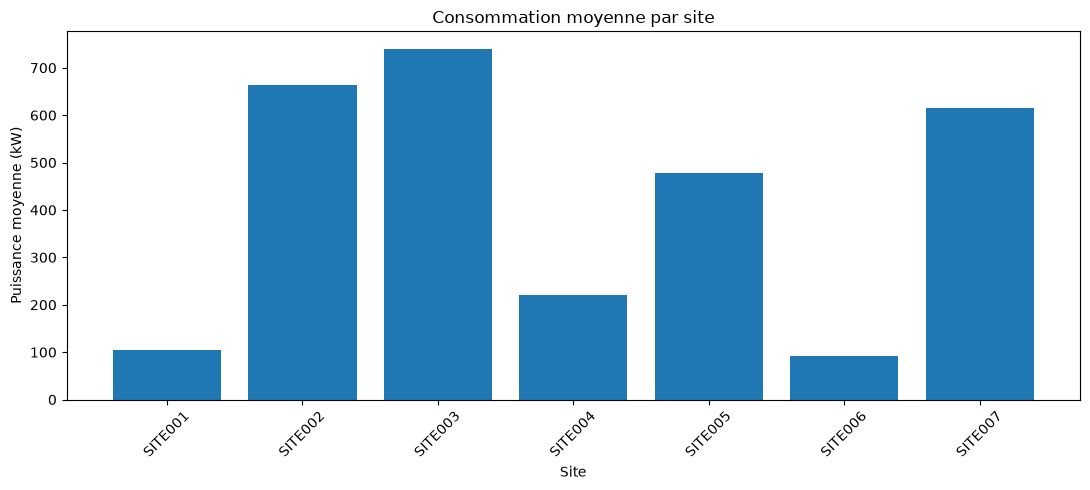

In [65]:
import matplotlib.pyplot as plt

site_stats_reset = site_stats.reset_index()

fig, ax = plt.subplots(figsize=(11, 5))

ax.bar(
    site_stats_reset["site_id"],
    site_stats_reset["mean_kw"],
)

ax.set_title("Consommation moyenne par site")
ax.set_xlabel("Site")
ax.set_ylabel("Puissance moyenne (kW)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

C - Comparaison des distributions

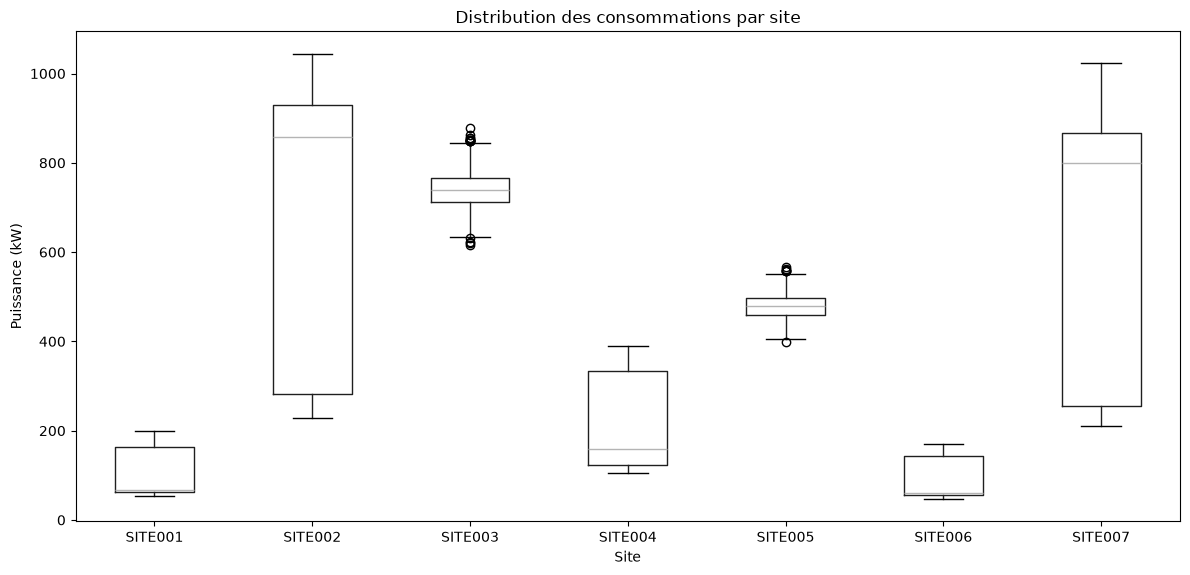

In [66]:
fig, ax = plt.subplots(figsize=(12, 6))

df.boxplot(
    column="consumption_kw",
    by="site_id",
    ax=ax,
    grid=False,
)

ax.set_title("Distribution des consommations par site")
ax.set_xlabel("Site")
ax.set_ylabel("Puissance (kW)")

plt.suptitle("")
plt.tight_layout()
plt.show()

D - Comparaison des sites d'un même type (Pour "office" et "factory")

In [67]:
for site_type in ["office", "factory"]:
    subset = df[df["site_type"] == site_type]

    print(f"\nType : {site_type}")

    display(
        subset.groupby("site_id")["consumption_kw"]
        .agg(["count", "mean", "median", "std", "min", "max"])
        .round(2)
    )


Type : office


,count,mean,median,std,min,max
site_id,,,,,,
SITE001,927,105.03,66.59,50.35,52.64,200.20
SITE006,947,91.98,59.49,43.00,46.47,169.81



Type : factory


,count,mean,median,std,min,max
site_id,,,,,,
SITE002,948,663.92,857.62,301.52,228.97,1044.66
SITE007,943,616.02,800.24,285.98,209.50,1022.74


### Conclusion — Comparaison des sites et stratégie de modélisation

L'analyse comparative des sept sites met en évidence des différences importantes de consommation énergétique selon les catégories de sites.

Les bureaux et les usines présentent des consommations moyennes relativement proches au sein de leur catégorie, ainsi que des coefficients de variation comparables.

À l'inverse, les profils du datacenter et de l'hôpital se distinguent par une consommation relativement stable, avec un coefficient de variation inférieur à 6 %, contre environ 45 à 48 % pour les autres sites.

Ces résultats suggèrent que le type de site constitue une variable potentiellement déterminante pour la modélisation énergétique.

Toutefois, les données provenant d'une API de simulation, ces différences peuvent également résulter de règles de génération spécifiques aux catégories de sites.

**Hypothèse retenue :** comparer expérimentalement trois approches de modélisation : globale, par catégorie de site et par site.

Le choix définitif reposera sur les performances prédictives, la capacité de généralisation et les contraintes de maintenance des modèles.

## 5 — Analyse temporelle des consommations

### Objectifs

Cette section vise à étudier la dimension temporelle des mesures énergétiques collectées depuis l'API EnerVision.

L'analyse portera sur :

- La couverture temporelle et la régularité des mesures.
- L'évolution de la consommation électrique sur une période de 24 heures.
- L'identification de cycles de consommation selon les sites et leurs catégories.
- La recherche de comportements temporels potentiellement exploitables pour la prédiction.

**Point de vigilance :** les précédentes expérimentations ont montré que les données historiques de l'API pouvaient être régénérées à chaque requête. La régularité des timestamps ne garantit donc pas l'existence d'un historique réel et stable.

A - Vérification de la couverture temporelle
 - Résultat attendu : Les sept sites doivent couvrir la même période (environ 24h)

In [68]:
temporal_coverage = (
    df.groupby("site_id")
    .agg(
        first_measure=("timestamp", "min"),
        last_measure=("timestamp", "max"),
        observations=("timestamp", "count"),
    )
)

temporal_coverage["duration_hours"] = (
    temporal_coverage["last_measure"]
    - temporal_coverage["first_measure"]
).dt.total_seconds() / 3600

display(temporal_coverage)

,first_measure,last_measure,observations,duration_hours
site_id,,,,
SITE001,2026-10-21 09:27:00.985617+00:00,2026-10-22 09:25:34.585617+00:00,1000,23.976
SITE002,2026-10-21 09:27:00.985617+00:00,2026-10-22 09:25:34.585617+00:00,1000,23.976
SITE003,2026-10-21 09:27:00.985617+00:00,2026-10-22 09:25:34.585617+00:00,1000,23.976
SITE004,2026-10-21 09:27:00.985617+00:00,2026-10-22 09:25:34.585617+00:00,1000,23.976
SITE005,2026-10-21 09:27:00.985617+00:00,2026-10-22 09:25:34.585617+00:00,1000,23.976
SITE006,2026-10-21 09:27:00.985617+00:00,2026-10-22 09:25:34.585617+00:00,1000,23.976
SITE007,2026-10-21 09:27:00.985617+00:00,2026-10-22 09:25:34.585617+00:00,1000,23.976


B - Analyse de la fréquence des mesures
- Attendu : Intervalles similaires

In [69]:
interval_stats = []

for site_id, group in df.groupby("site_id"):

    timestamps = group["timestamp"].sort_values()

    intervals = (
        timestamps.diff()
        .dt.total_seconds()
        .dropna()
    )

    interval_stats.append({
        "site_id": site_id,
        "mean_interval_s": intervals.mean(),
        "median_interval_s": intervals.median(),
        "std_interval_s": intervals.std(),
        "min_interval_s": intervals.min(),
        "max_interval_s": intervals.max(),
    })

interval_df = pd.DataFrame(interval_stats)

display(interval_df.round(4))

,site_id,mean_interval_s,median_interval_s,std_interval_s,min_interval_s,max_interval_s
0,SITE001,86.4,86.4,0.0,86.4,86.4
1,SITE002,86.4,86.4,0.0,86.4,86.4
2,SITE003,86.4,86.4,0.0,86.4,86.4
3,SITE004,86.4,86.4,0.0,86.4,86.4
4,SITE005,86.4,86.4,0.0,86.4,86.4
5,SITE006,86.4,86.4,0.0,86.4,86.4
6,SITE007,86.4,86.4,0.0,86.4,86.4


C - Visualisation de la consommation sur 24h

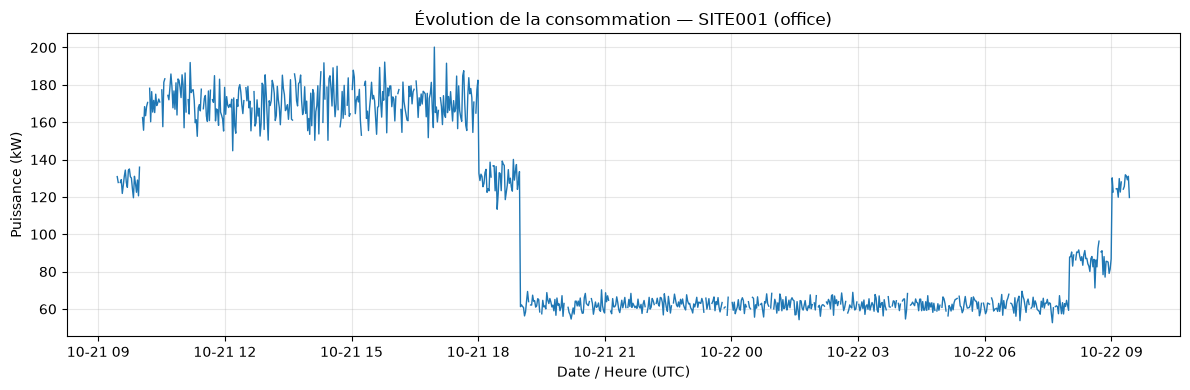

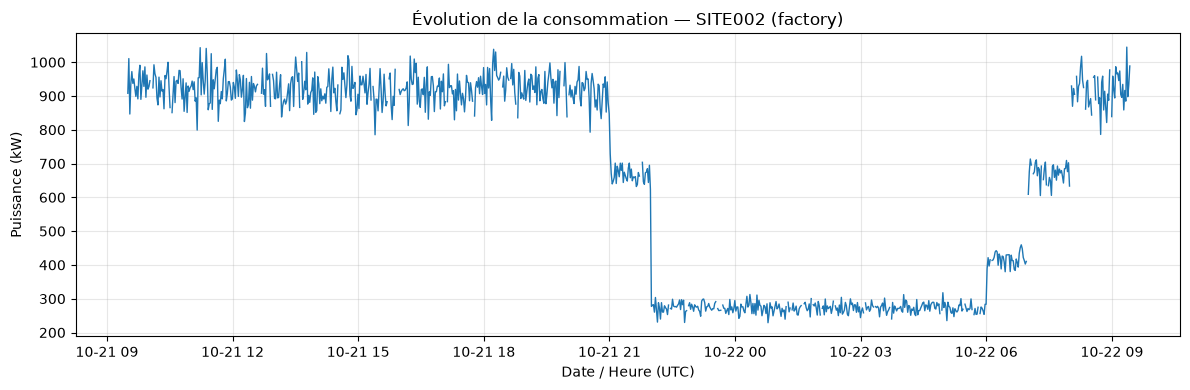

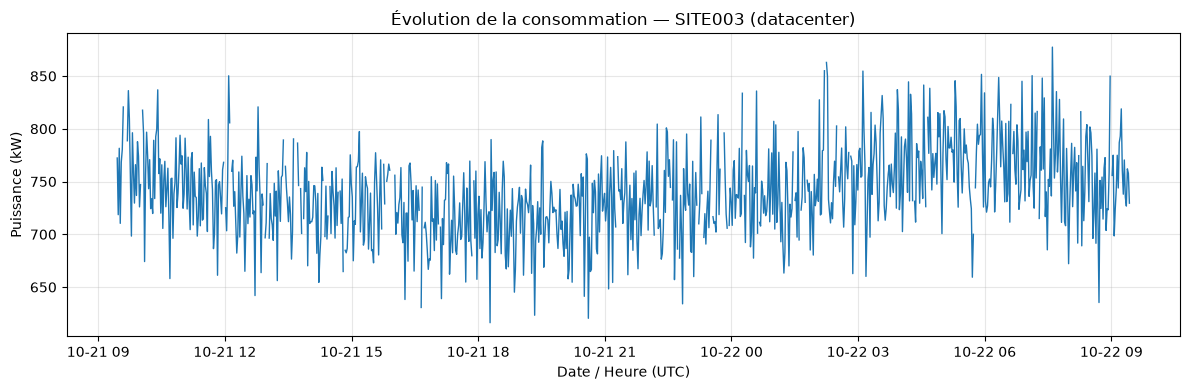

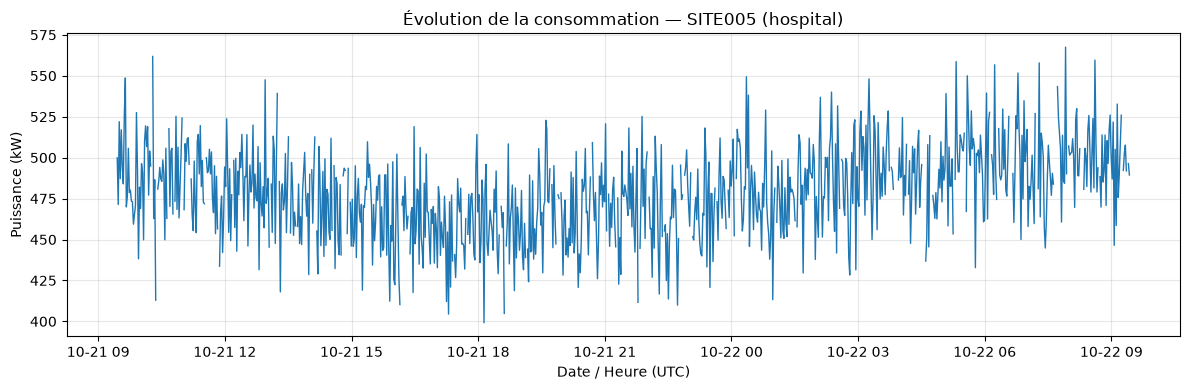

In [70]:
sites_to_plot = [
    "SITE001",  # Bureau
    "SITE002",  # Usine
    "SITE003",  # Datacenter
    "SITE005",  # Hôpital
]

for site_id in sites_to_plot:

    site_df = (
        df[df["site_id"] == site_id]
        .sort_values("timestamp")
    )

    site_type = site_df["site_type"].iloc[0]

    fig, ax = plt.subplots(figsize=(12, 4))

    ax.plot(
        site_df["timestamp"],
        site_df["consumption_kw"],
        linewidth=1,
    )

    ax.set_title(
        f"Évolution de la consommation — {site_id} ({site_type})"
    )

    ax.set_xlabel("Date / Heure (UTC)")
    ax.set_ylabel("Puissance (kW)")
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

5 - Comparaison des profils horaires

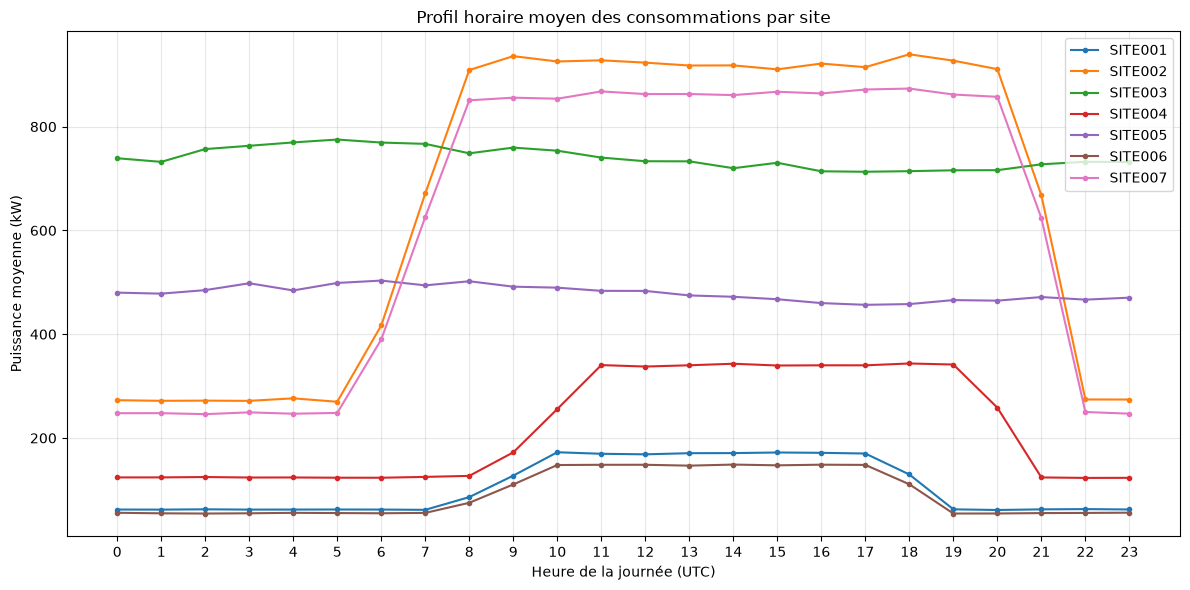

In [71]:
# Création d'une colonne horaire pour l'analyse
df["hour"] = df["timestamp"].dt.hour

hourly_consumption = (
    df.groupby(["site_id", "hour"])["consumption_kw"]
    .mean()
    .reset_index()
)

fig, ax = plt.subplots(figsize=(12, 6))

for site_id, group in hourly_consumption.groupby("site_id"):
    ax.plot(
        group["hour"],
        group["consumption_kw"],
        marker="o",
        markersize=3,
        label=site_id,
    )

ax.set_title("Profil horaire moyen des consommations par site")
ax.set_xlabel("Heure de la journée (UTC)")
ax.set_ylabel("Puissance moyenne (kW)")
ax.set_xticks(range(24))
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Conclusion — Analyse temporelle

L'analyse des 7 000 observations met en évidence une grille temporelle parfaitement régulière, avec un intervalle constant de 86,4 secondes entre les mesures.

Cette régularité, identique pour les sept sites, renforce l'hypothèse d'une génération synthétique des timestamps par l'API EnerVision.

L'étude des courbes de consommation révèle également des profils temporels distincts selon les catégories de bâtiments :

- Les bureaux et les usines présentent une forte variation entre les périodes d'activité et d'inactivité.
- Le commerce suit également un cycle journalier marqué.
- Le datacenter et l'hôpital présentent une consommation relativement stable, compatible avec une activité continue.

Les sites appartenant à une même catégorie semblent partager des profils horaires similaires, ce qui renforce l'intérêt d'une modélisation tenant compte du type de bâtiment.

**Hypothèse de modélisation :** les variables temporelles, notamment l'heure de la journée, associées au type de site, pourraient constituer des caractéristiques importantes pour la prédiction de consommation.

**Limites :** les données proviennent d'une API de simulation dont les valeurs peuvent varier entre deux requêtes identiques. Les observations couvrent une seule période de 24 heures et ne permettent pas de confirmer la répétabilité des cycles ni la capacité de généralisation des futurs modèles.

## 6 — Analyse des corrélations

### Objectifs

Cette section vise à étudier les relations statistiques entre les différentes variables numériques du dataset EnerVision afin d'identifier les caractéristiques potentiellement pertinentes pour la prédiction énergétique.

L'analyse portera sur :

- Les corrélations globales entre les mesures.
- Les corrélations propres à chaque site.
- Les différences de corrélation selon les catégories de bâtiments.
- L'identification des variables redondantes ou potentiellement problématiques pour la modélisation.

Les corrélations seront calculées avec le coefficient de Pearson, qui mesure les relations linéaires entre deux variables.

**Précautions :** une corrélation n'implique pas une relation causale. De plus, les données étant synthétiques, les associations observées peuvent résulter des règles du générateur EnerVision.

A - Matrice de corrélation globale
- Examen des relation entre toutes les variables numériques
- Dans ce premier exemple, consumption_kwh est retiré, car strictement identique à consumption_kw

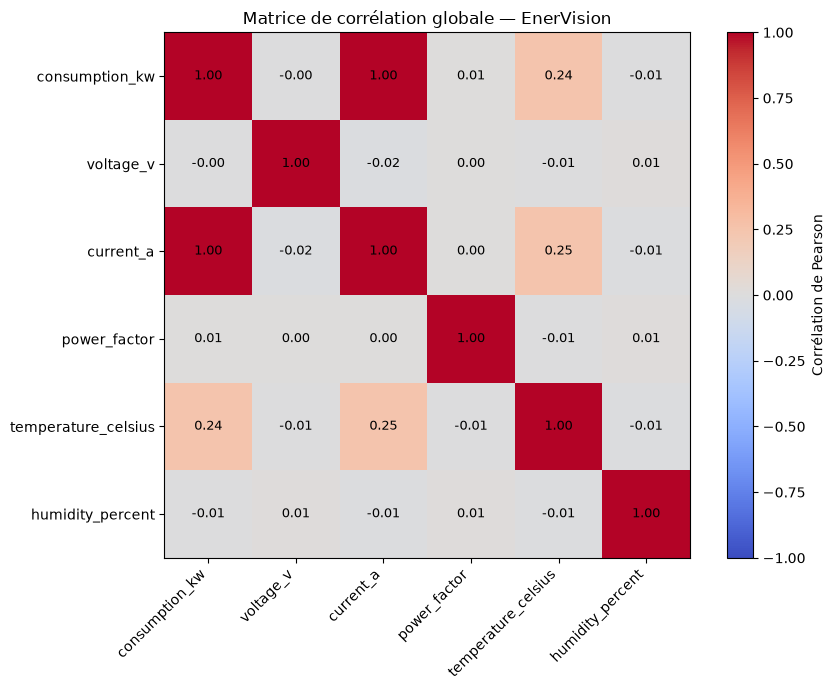

In [72]:
import matplotlib.pyplot as plt
import pandas as pd

numeric_columns = [
    "consumption_kw",
    "voltage_v",
    "current_a",
    "power_factor",
    "temperature_celsius",
    "humidity_percent",
]

global_corr = df[numeric_columns].corr(method="pearson")

fig, ax = plt.subplots(figsize=(9, 7))

im = ax.imshow(global_corr, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(numeric_columns)))
ax.set_yticks(range(len(numeric_columns)))

ax.set_xticklabels(numeric_columns, rotation=45, ha="right")
ax.set_yticklabels(numeric_columns)

for i in range(len(numeric_columns)):
    for j in range(len(numeric_columns)):
        ax.text(
            j,
            i,
            f"{global_corr.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=9,
        )

fig.colorbar(im, ax=ax, label="Corrélation de Pearson")

ax.set_title("Matrice de corrélation globale — EnerVision")

plt.tight_layout()
plt.show()

B - Corrélation avec la consommation, par site
- Nous avons vu que les bâtiments possèdent des niveaux de consommation très différents. Une forte corrélation globale pourrait donc simplement refléter ces différences.

In [73]:
site_correlations = []

for site_id, group in df.groupby("site_id"):
    correlations = group[numeric_columns].corr()["consumption_kw"]

    site_correlations.append({
        "site_id": site_id,
        "site_type": group["site_type"].iloc[0],
        **correlations.to_dict(),
    })

site_corr_df = pd.DataFrame(site_correlations)

display(
    site_corr_df.round(3)
)

,site_id,site_type,consumption_kw,voltage_v,current_a,power_factor,temperature_celsius,humidity_percent
0,SITE001,office,1.0,0.000,1.000,0.026,0.733,-0.037
1,SITE002,factory,1.0,-0.023,1.000,0.060,0.694,0.053
2,SITE003,datacenter,1.0,0.018,0.977,-0.084,-0.043,0.048
3,SITE004,retail,1.0,-0.001,1.000,0.044,0.571,-0.009
4,SITE005,hospital,1.0,-0.001,0.976,-0.016,0.006,0.061
5,SITE006,office,1.0,0.000,1.000,0.024,0.745,0.031
6,SITE007,factory,1.0,-0.008,1.000,-0.043,0.681,-0.066


C - Visualisation des corrélations par site
- Heatmap permettant de repérer les relations communes aux sept sites et celles qui semble spécifiques à certaines catégories

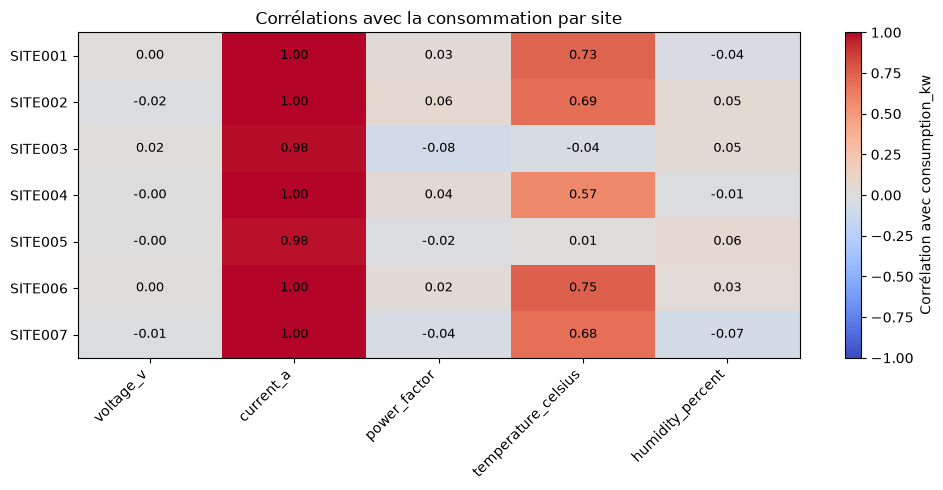

In [74]:
site_corr_matrix = site_corr_df.set_index("site_id")[
    [col for col in numeric_columns if col != "consumption_kw"]
]

fig, ax = plt.subplots(figsize=(10, 5))

im = ax.imshow(
    site_corr_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    aspect="auto",
)

ax.set_xticks(range(len(site_corr_matrix.columns)))
ax.set_xticklabels(
    site_corr_matrix.columns,
    rotation=45,
    ha="right",
)

ax.set_yticks(range(len(site_corr_matrix.index)))
ax.set_yticklabels(site_corr_matrix.index)

for i in range(len(site_corr_matrix.index)):
    for j in range(len(site_corr_matrix.columns)):
        value = site_corr_matrix.iloc[i, j]

        ax.text(
            j,
            i,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=9,
        )

fig.colorbar(im, ax=ax, label="Corrélation avec consumption_kw")
ax.set_title("Corrélations avec la consommation par site")

plt.tight_layout()
plt.show()

D - Comparaison des corrélations globales et intra-sites
- Tableau comparatif

In [75]:
comparison = pd.DataFrame({
    "global_correlation": global_corr["consumption_kw"],
    "mean_site_correlation": (
        site_corr_df
        .drop(columns=["site_id", "site_type"])
        .mean()
    ),
})

comparison["difference"] = (
    comparison["global_correlation"]
    - comparison["mean_site_correlation"]
)

display(
    comparison.round(3)
)

,global_correlation,mean_site_correlation,difference
consumption_kw,1.000,1.000,0.000
voltage_v,-0.000,-0.002,0.002
current_a,1.000,0.993,0.007
power_factor,0.006,0.002,0.005
temperature_celsius,0.242,0.484,-0.242
humidity_percent,-0.007,0.012,-0.018


E - Bonus : Vérification corrélation température après retrait moyenne horaire propre à chaque site

In [76]:
# Corrélation après retrait de la moyenne horaire propre à chaque site
df["hour"] = df["timestamp"].dt.hour

columns = ["consumption_kw", "temperature_celsius"]

residuals = df[columns] - df.groupby(
    ["site_id", "hour"]
)[columns].transform("mean")

residuals["site_id"] = df["site_id"]

results = []

for site_id, group in residuals.groupby("site_id"):
    results.append({
        "site_id": site_id,
        "corr_after_hour_control": group[
            "consumption_kw"
        ].corr(group["temperature_celsius"]),
    })

display(pd.DataFrame(results).round(3))

,site_id,corr_after_hour_control
0,SITE001,0.017
1,SITE002,0.001
2,SITE003,-0.029
3,SITE004,-0.074
4,SITE005,-0.056
5,SITE006,0.019
6,SITE007,-0.025


### Conclusion — Analyse des corrélations

L'analyse des corrélations met en évidence une relation presque parfaite entre la consommation électrique (`consumption_kw`) et l'intensité (`current_a`), aussi bien globalement qu'au sein des différents sites.

Cette relation devra être prise en compte lors de la sélection des variables explicatives afin d'éviter de construire un modèle de prévision reposant sur des mesures contemporaines indisponibles au moment de la prédiction.

La température présente des corrélations positives relativement importantes pour les bureaux, les usines et le commerce, tandis que cette relation est quasiment inexistante pour le datacenter et l'hôpital.

Ces différences renforcent l'hypothèse selon laquelle les caractéristiques pertinentes pour la modélisation dépendent du type de bâtiment.

En revanche, les autres variables étudiées présentent peu de corrélations linéaires avec la consommation.

**Orientations retenues :**

- Privilégier les variables temporelles et les caractéristiques des sites comme premières variables explicatives.
- Évaluer l'apport de la température et des autres mesures environnementales.
- Éviter les variables directement dérivées de la consommation cible.
- Comparer les performances des modèles globaux et spécialisés.
- Conserver les indicateurs de qualité pour les futurs traitements.

**Limites :** les relations observées concernent des données synthétiques couvrant une seule journée. Elles ne permettent pas de conclure à des relations causales ni de garantir leur stabilité sur d'autres périodes.

## 7 — Synthèse et conclusion de l'analyse exploratoire

### 7.1 — Objectifs et périmètre

Cette première analyse exploratoire avait pour objectif d'étudier la structure, la qualité et le comportement des données énergétiques fournies par l'API EnerVision, afin d'évaluer leur pertinence pour la mise en œuvre de modèles de Machine Learning.

L'étude repose sur un échantillon de **7 000 mesures**, réparties équitablement entre sept sites appartenant à cinq catégories de bâtiments : bureaux, usines, datacenter, commerce et hôpital.

Les observations couvrent une période de 24 heures. Les analyses ont porté sur la qualité des données, les valeurs manquantes, les différences entre sites, les profils temporels et les corrélations entre variables.

### 7.2 — Qualité et cohérence des données

L'analyse a révélé que 78,8 % des observations sont classées `good`, tandis que les 21,2 % restantes présentent différents niveaux de dégradation (`partial`, `degraded` ou `critical`).

Les valeurs manquantes sont étroitement liées aux indicateurs `data_quality` et `null_reasons`. Les observations de bonne qualité sont complètes, tandis que les autres catégories présentent des absences cohérentes avec leur niveau de dégradation.

Les causes déclarées concernent notamment les défaillances de capteurs de température, d'humidité, de consommation ou de mesures électriques, ainsi que les pertes de communication.

Ces résultats montrent que les valeurs manquantes constituent une information pertinente pour caractériser la qualité des mesures.

**Décision retenue :** conserver l'intégralité des observations brutes et leurs métadonnées. Les stratégies d'exclusion ou d'imputation seront définies ultérieurement selon les besoins de chaque modèle.

Une anomalie supplémentaire a été identifiée : les variables `consumption_kw` et `consumption_kwh` présentent des valeurs strictement identiques sur les 6 591 observations comparables. Cette redondance devra être prise en compte lors du prétraitement, les deux variables représentant théoriquement des grandeurs physiques différentes.

### 7.3 — Différences entre sites et catégories

L'étude comparative a mis en évidence des profils énergétiques distincts selon les catégories de bâtiments.

Les bureaux, les usines et le commerce présentent une forte variabilité de consommation, avec des coefficients de variation compris approximativement entre 45 et 48 %.

À l'inverse, le datacenter et l'hôpital présentent une consommation relativement stable, avec des coefficients de variation proches de 5 à 6 %.

Les sites appartenant à une même catégorie, notamment les deux bureaux et les deux usines, présentent des distributions et des niveaux de variabilité similaires.

Ces observations suggèrent que le type de bâtiment constitue une caractéristique potentiellement importante pour la modélisation énergétique.

**Hypothèse retenue :** comparer expérimentalement trois stratégies de modélisation : un modèle global, des modèles spécialisés par catégorie et des modèles individualisés par site.

Le choix définitif devra reposer sur des évaluations prédictives et non uniquement sur les différences statistiques observées.

### 7.4 — Comportements temporels

Les sept sites présentent une grille temporelle identique, avec un intervalle constant de 86,4 secondes entre deux observations successives.

Cette régularité renforce l'hypothèse d'une génération synthétique des timestamps par l'API, plutôt que d'une restitution d'un historique de mesures réellement enregistrées.

L'analyse des courbes de consommation a néanmoins permis d'identifier des profils journaliers cohérents avec les catégories de bâtiments :

- Les bureaux présentent une augmentation de consommation pendant les heures d'activité.
- Les usines montrent des variations importantes entre les périodes de production et d'inactivité.
- Le commerce présente également un cycle journalier marqué.
- Le datacenter et l'hôpital maintiennent une consommation relativement stable sur l'ensemble de la période.

Les profils observés suggèrent que **l'heure de la journée et le type de bâtiment constituent des variables explicatives prioritaires**.

Toutefois, la période étudiée ne permet pas de vérifier la répétabilité des cycles sur plusieurs jours, ni d'étudier les différences entre jours ouvrés, week-ends et saisons.

7.5 — Corrélations et sélection des variables

L'analyse des corrélations a mis en évidence une relation presque parfaite entre consumption_kw et current_a, avec des coefficients proches de 1.

Cette relation, compatible avec les principes électriques, nécessite une vigilance particulière : l'utilisation du courant mesuré au même instant que la consommation pourrait produire de très bonnes performances apparentes sans répondre à l'objectif de prévision de consommation future.

La température présentait initialement des corrélations positives relativement élevées avec la consommation pour les bureaux, les usines et le commerce.

Cependant, après retrait des moyennes horaires propres à chaque site, ces corrélations deviennent proches de zéro.

Ce résultat suggère que les associations initiales s'expliquent principalement par des variations temporelles communes, plutôt que par une relation linéaire indépendante entre température et consommation sur la période étudiée.

Cette observation ne permet toutefois pas d'écarter l'intérêt des variables météorologiques. Leur influence pourrait être plus importante à l'échelle hebdomadaire ou saisonnière, notamment en raison des besoins de chauffage et de climatisation.

Décision retenue : privilégier les variables temporelles et les caractéristiques des sites, tout en conservant les variables environnementales comme candidates à évaluer expérimentalement.

7.6 — Limites de l'étude

Plusieurs limites doivent être prises en compte avant toute phase d'entraînement.

Nature synthétique des données : les précédents tests de l'API ont montré que des requêtes identiques pouvaient produire des valeurs différentes pour les mêmes timestamps. Les modèles risquent donc d'apprendre les règles du générateur plutôt que des comportements énergétiques réellement observés.

Couverture temporelle limitée : l'échantillon actuel couvre uniquement 24 heures, ce qui ne permet pas d'étudier la saisonnalité, les différences hebdomadaires ou la stabilité des profils dans le temps.

Représentativité des catégories : certaines catégories de bâtiments ne comportent qu'un seul site, ce qui limite l'évaluation de la généralisation des modèles spécialisés.

Disponibilité des variables : certaines mesures, notamment les grandeurs électriques contemporaines, ne seront pas nécessairement disponibles au moment où une prévision devra être réalisée.

Enfin, les résultats obtenus décrivent des associations statistiques et ne permettent pas d'établir de relations causales.

7.7 — Perspectives et prochaines étapes

Cette première exploration fournit une base pour préparer les futurs traitements et expérimentations de Machine Learning.

Avant de procéder à l'entraînement, deux analyses complémentaires sont envisagées.

Analyse hebdomadaire : étendre la collecte à sept jours afin d'étudier les différences entre jours ouvrés et week-ends, ainsi que la cohérence entre les métadonnées de statut des sites et les consommations observées.

Analyse annuelle : étudier les variations saisonnières et réévaluer l'intérêt de la température et de l'humidité sur une période plus représentative.

Ces analyses permettront de préciser les caractéristiques pertinentes, d'identifier d'éventuelles incohérences supplémentaires et de mieux définir les conditions d'évaluation des modèles.

7.8 — Conclusion générale

Cette première analyse exploratoire a permis de mieux comprendre la structure et les particularités des données EnerVision.

Elle met en évidence des profils de consommation distincts selon les catégories de bâtiments, une organisation cohérente des indicateurs de qualité et des cycles journaliers potentiellement exploitables pour la prédiction.

Elle révèle également plusieurs points de vigilance, notamment la redondance de certaines variables, les corrélations liées aux cycles horaires et les limites inhérentes à la génération synthétique des données.

À ce stade, aucune stratégie de modélisation ne peut être considérée comme définitivement supérieure.

La démarche retenue consiste donc à approfondir l'analyse temporelle avant de préparer plusieurs configurations de modèles, dont les performances seront comparées de manière reproductible avec MLflow.

Cette approche doit permettre de justifier les choix techniques à partir des observations et des résultats expérimentaux, plutôt que de présupposer la pertinence d'un algorithme ou d'une architecture particulière.